# PoseForge — GRU sequence classifier (frozen processed V2)

**Goal:** compare a causal GRU with the established MLP without changing production MLP weights. Uses the **same 13-joint × 4-channel (52 feature) representation** and frozen subject-wise train/validation/test split. **No preprocessing, pose re-extraction or raw video is needed.**

- Only validation decides architecture, epoch and regularization. Test is opened **once after final retraining**.
- Window is causal (past + current frame), reset for missing pose and at clip boundaries; zeros left-pad the first frames.
- Each original source take × camera contributes at most 48 training anchors/epoch to reduce correlated windows.
- Model remains **PT FP32**. Outputs include final checkpoint for UI, model comparison, charts, evaluation and a small review ZIP. No overwrite of existing runs.

## 1. Setup / processed ZIP location

In [ ]:
import os, io, sys, json, random, hashlib, shutil, zipfile, math, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
DRIVE_ROOT = Path('/content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu')
ROOT = Path(os.environ['POSEFORGE_ROOT']).expanduser() if os.environ.get('POSEFORGE_ROOT') else (
    DRIVE_ROOT if DRIVE_ROOT.is_dir() else next((p for p in (Path.cwd(), *Path.cwd().parents)
                        if (p/'shared/gru_model.py').is_file()), Path.cwd()))
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from shared.gru_model import PostureGRU
from shared.gru_training import read_index, load_clips, quota_anchors, augment_windows
PROCESSED_ZIP = Path(os.environ.get('POSEFORGE_PROCESSED_ZIP',
    ROOT/'artifacts/outputs/phase2_v2/41774c321098/processed/pose13_features.zip'))
if not PROCESSED_ZIP.is_file():
    matches = sorted(ROOT.glob('**/processed/pose13_features.zip'))
    if len(matches) == 1: PROCESSED_ZIP = matches[0]
assert PROCESSED_ZIP.is_file(), f'Set POSEFORGE_PROCESSED_ZIP to the processed ZIP: {PROCESSED_ZIP}'
DEVICE = torch.device(os.environ.get('POSEFORGE_DEVICE', 'cuda:0' if torch.cuda.is_available() else 'cpu'))
RUN_FINAL = True           # True = final retrain and single held-out test
CONFIRM_SEEDS = (303, 304) # Confirm top two candidates; set () for fast experiment only
SEED = 302
LABELS = ['Upright','Hunched','Head on desk','Leaning back','Side lean/turn','Hand raised']
CANDIDATES = [
    dict(name='GRU-64 / 16',sequence_length=16,hidden_size=64,num_layers=1,dropout=.20),
    dict(name='GRU-64x2 / 16',sequence_length=16,hidden_size=64,num_layers=2,dropout=.20),
    dict(name='GRU-64 / 24',sequence_length=24,hidden_size=64,num_layers=1,dropout=.20),
]

TRAIN_CFG = dict(lr=1e-3,weight_decay=1e-3,epochs=80,patience=12,batch_size=128,
                 max_per_source_camera=48,flip_prob=.5,jitter_std=.008)
print('Input:', PROCESSED_ZIP, '| device:', DEVICE, '| run final:', RUN_FINAL)

Mounted at /content/drive
Input: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/outputs/phase2_v2/41774c321098/processed/pose13_features.zip | device: cuda:0 | run final: True


## 2. Frozen dataset contract — only train/validation opened here

In [2]:
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(4*1024*1024), b''):h.update(b)
    return h.hexdigest()
PROCESSED_SHA = sha256(PROCESSED_ZIP)
if str(PROCESSED_ZIP).startswith('/content/drive/'):
    local = Path('/content')/f'processed_gru_{PROCESSED_SHA[:12]}.zip'
    if not local.exists() or sha256(local)!=PROCESSED_SHA: shutil.copy2(PROCESSED_ZIP,local)
else: local = PROCESSED_ZIP
index, contract, split, prefix = read_index(local)
assert contract['version'] == 'pose13_xy_conf_mask_causal_v2'
assert set(index.label.astype(int)) == set(range(6))
assert not (set(split['train_people']) & set(split['validation_people']))
assert not (set(split['test_people']) & (set(split['train_people'])|set(split['validation_people'])))
cache = {}
def clips_for(split_names, length):
    key=(tuple(split_names),length)
    if key not in cache: cache[key]=load_clips(local,index,prefix,split_names,length)
    return cache[key]
for part in ('train','val','test'):
    rows=index[index.split==part]
    print(part, 'subjects:',rows.person_id.nunique(), 'clips:',len(rows), 'frames:',int(rows.frames.sum()))
print('All:',len(index),'clips,',int(index.frames.sum()),'frames | SHA',PROCESSED_SHA[:16])

train subjects: 11 clips: 164 frames: 16949
val subjects: 2 clips: 30 frames: 4206
test subjects: 1 clips: 12 frames: 841
All: 206 clips, 21996 frames | SHA 99fedbbbd7e3d0f3


## 3. Training and validation helpers

In [3]:
def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def build_model(cfg):
    return PostureGRU(cfg['hidden_size'],cfg['num_layers'],cfg['dropout']).to(DEVICE)

def train_epoch(model,optimizer,clips,cfg,epoch,seed):
    model.train()
    anchors=quota_anchors(clips,epoch,seed,TRAIN_CFG['max_per_source_camera'])
    if not anchors: raise ValueError('No train anchors')
    rng=np.random.default_rng(seed*1009+epoch)
    generator=torch.Generator(device=DEVICE).manual_seed(seed*100003+epoch)
    losses=[]
    for start in range(0,len(anchors),TRAIN_CFG['batch_size']):
        batch=anchors[start:start+TRAIN_CFG['batch_size']]
        X=np.stack([clips[c]['windows'][i] for c,i in batch]); Y=np.array([clips[c]['label'] for c,i in batch],np.int64)
        xb=augment_windows(torch.from_numpy(X).to(DEVICE),generator,
                            TRAIN_CFG['flip_prob'],TRAIN_CFG['jitter_std'])
        yb=torch.from_numpy(Y).to(DEVICE)
        loss=nn.functional.cross_entropy(model(xb),yb)
        optimizer.zero_grad(set_to_none=True);loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.)
        optimizer.step();losses.append(float(loss.detach().cpu()))
    return float(np.mean(losses)),len(anchors)

@torch.inference_mode()
def evaluate(model,clips):
    model.eval();rows=[]
    for c in clips:
        idx=np.flatnonzero(c['valid']);probs=[]
        for start in range(0,len(idx),512):
            ids=idx[start:start+512]
            xb=torch.from_numpy(c['windows'][ids]).to(DEVICE)
            probs.append(torch.softmax(model(xb),1).cpu().numpy())
        if not probs: continue
        probs=np.concatenate(probs)
        for fid, pr in zip(idx,probs):
            rows.append(dict(person=c['person'],clip_id=c['clip_id'],source=c['source'],camera=c['camera'],
                frame=int(fid),label=c['label'],pred=int(pr.argmax()),true_prob=float(pr[c['label']]),
                probability_vector=pr))
    df=pd.DataFrame(rows)
    if df.empty:raise ValueError('No valid eval frames')
    by_person=df.groupby('person',sort=True).apply(
        lambda x:f1_score(x.label,x.pred,labels=list(range(6)),average='macro',zero_division=0),
        include_groups=False)
    group=df.groupby('source',sort=True).apply(
        lambda x:int(np.mean(np.stack(x.probability_vector.to_list()),axis=0).argmax())==int(x.label.iloc[0]),
        include_groups=False)
    p=np.clip(df.true_prob.to_numpy(),1e-9,1)
    scores=dict(frame_accuracy=float(accuracy_score(df.label,df.pred)),
        frame_macro_f1=float(f1_score(df.label,df.pred,labels=list(range(6)),average='macro',zero_division=0)),
        subject_macro_f1=float(by_person.mean()),min_subject_macro_f1=float(by_person.min()),
        source_accuracy=float(group.mean()),nll=float(-np.log(p).mean()),n_frames=len(df))
    return scores,df

def train_candidate(cfg, seed, folder):
    seed_all(seed)
    train=clips_for(('train',),cfg['sequence_length']);valid=clips_for(('val',),cfg['sequence_length'])
    model=build_model(cfg)
    optimizer=torch.optim.AdamW(model.parameters(),lr=TRAIN_CFG['lr'],weight_decay=TRAIN_CFG['weight_decay'])
    best_key=None;best_epoch=0;stale=0;history=[]
    folder.mkdir(parents=True,exist_ok=False)
    for epoch in range(1,TRAIN_CFG['epochs']+1):
        loss,n=train_epoch(model,optimizer,train,cfg,epoch,seed)
        metrics,_=evaluate(model,valid)
        key=(metrics['subject_macro_f1'],metrics['min_subject_macro_f1'],metrics['source_accuracy'],-metrics['nll'])
        history.append(dict(epoch=epoch,train_loss=loss,train_samples=n,**{'val_'+k:v for k,v in metrics.items()}))
        if best_key is None or key>best_key:
            best_key=key;best_epoch=epoch;stale=0
            torch.save({k:v.detach().cpu().clone() for k,v in model.state_dict().items()},folder/'best_state.pt')
        else: stale+=1
        if stale>=TRAIN_CFG['patience']:break
    pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
    model.load_state_dict(torch.load(folder/'best_state.pt',map_location=DEVICE,weights_only=True))
    best,_=evaluate(model,valid)
    (folder/'summary.json').write_text(json.dumps(dict(candidate=cfg['name'],seed=seed,
        best_epoch=best_epoch,epochs_run=len(history),**best),indent=2))
    return dict(candidate=cfg['name'],seed=seed,best_epoch=best_epoch,**best)

## 4. Candidate comparison — frozen validation only

,candidate,best_epoch,subject_macro_f1,min_subject_macro_f1,source_accuracy,nll
0,GRU-64 / 16,14,0.939952,0.898618,0.933333,0.294407
1,GRU-64x2 / 16,9,0.933164,0.882017,0.933333,0.321251
2,GRU-64 / 24,4,0.928832,0.862996,0.933333,0.284024


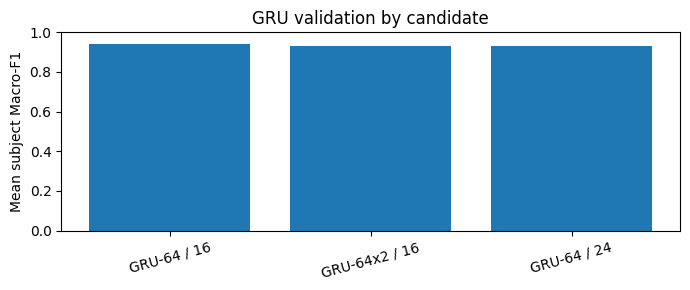

In [4]:
BASE = ROOT/'artifacts/outputs/gru_training'
BASE.mkdir(parents=True,exist_ok=True)
RUN_DIR=next(BASE/f'gru_experiment_{i:03d}' for i in range(1,10000)
             if not (BASE/f'gru_experiment_{i:03d}').exists())
RUN_DIR.mkdir(exist_ok=False)
(RUN_DIR/'feature_contract.json').write_text(json.dumps(contract,indent=2))
(RUN_DIR/'experiment_config.json').write_text(json.dumps(dict(config=TRAIN_CFG,candidates=CANDIDATES,
    split=split,processed_sha256=PROCESSED_SHA),indent=2))
results=[]
for cfg in CANDIDATES:
    folder=RUN_DIR/'candidates'/cfg['name'].replace('/','_').replace(' ','_')
    r=train_candidate(cfg,SEED,folder)
    results.append(r)
comparison=pd.DataFrame(results).sort_values(
    ['subject_macro_f1','min_subject_macro_f1','source_accuracy','nll','candidate'],
    ascending=[False,False,False,True,True],kind='mergesort')
comparison.to_csv(RUN_DIR/'candidate_comparison.csv',index=False)
display(comparison[['candidate','best_epoch','subject_macro_f1','min_subject_macro_f1','source_accuracy','nll']])
fig,ax=plt.subplots(figsize=(7,3));ax.bar(comparison.candidate,comparison.subject_macro_f1)
ax.set(title='GRU validation by candidate',ylabel='Mean subject Macro-F1',ylim=(0,1))
plt.xticks(rotation=15);plt.tight_layout();fig.savefig(RUN_DIR/'candidate_comparison.png',dpi=150);plt.show();plt.close(fig)

## 5. Confirm top two across seeds 302–304; select with validation only

In [5]:
shortlist=comparison.head(2).candidate.tolist()
confirm=[r for r in results if r['candidate'] in shortlist]
for name in shortlist:
    cfg=next(c for c in CANDIDATES if c['name']==name)
    for seed in CONFIRM_SEEDS:
        folder=RUN_DIR/'confirmation'/name.replace('/','_').replace(' ','_')/str(seed)
        confirm.append(train_candidate(cfg,seed,folder))
confirmed=pd.DataFrame(confirm)
ranking=confirmed.groupby('candidate').agg(
    mean_f1=('subject_macro_f1','mean'),sd_f1=('subject_macro_f1','std'),
    min_f1=('min_subject_macro_f1','mean'),mean_source=('source_accuracy','mean'),
    mean_nll=('nll','mean'),median_epoch=('best_epoch','median')).reset_index().sort_values(
    ['mean_f1','min_f1','mean_source','mean_nll','candidate'],ascending=[False,False,False,True,True])
ranking.to_csv(RUN_DIR/'confirmed_ranking.csv',index=False)
winner_name=str(ranking.iloc[0].candidate)
winner_cfg=next(c for c in CANDIDATES if c['name']==winner_name)
final_epochs=max(1,int(round(float(ranking.iloc[0].median_epoch))))
selection=dict(winner=winner_name,final_epochs=final_epochs,seeds=[SEED,*CONFIRM_SEEDS],
    selection_metric='validation mean per-subject Macro-F1; test unused')
(RUN_DIR/'selection.json').write_text(json.dumps(selection,indent=2))
display(ranking);print('Selected:',winner_name,'| final epochs:',final_epochs)

,candidate,mean_f1,sd_f1,min_f1,mean_source,mean_nll,median_epoch
1,GRU-64x2 / 16,0.933398,0.017053,0.897683,0.977778,0.277110,4.0
0,GRU-64 / 16,0.930809,0.017578,0.888856,0.933333,0.320246,14.0


Selected: GRU-64x2 / 16 | final epochs: 4


## 6. Final retrain: Train+Validation (13 people). Evaluate held-out Test ONCE

In [6]:
if RUN_FINAL:
    seed_all(SEED+10000)
    model=build_model(winner_cfg)
    optimizer=torch.optim.AdamW(model.parameters(),lr=TRAIN_CFG['lr'],weight_decay=TRAIN_CFG['weight_decay'])
    final_train=clips_for(('train','val'),winner_cfg['sequence_length'])
    final_folder=RUN_DIR/'final';final_folder.mkdir()
    final_history=[]
    for epoch in range(1,final_epochs+1):
        loss,num=train_epoch(model,optimizer,final_train,winner_cfg,epoch,SEED+10000)
        final_history.append(dict(epoch=epoch,train_loss=loss,train_samples=num))
    pd.DataFrame(final_history).to_csv(final_folder/'history.csv',index=False)
    # Deliberately no TEST access before candidate selection + final retrain.
    heldout=clips_for(('test',),winner_cfg['sequence_length'])
    test_metrics,test_rows=evaluate(model,heldout)
    summary=dict(model_family='gru',candidate=winner_name,epochs=final_epochs,
        processed_sha256=PROCESSED_SHA,train_people=sorted(set(split['train_people'])|set(split['validation_people'])),
        test_people=split['test_people'],test_independent=True,test_metrics=test_metrics)
    (final_folder/'final_summary.json').write_text(json.dumps(summary,indent=2))
    report=classification_report(test_rows.label,test_rows.pred,labels=list(range(6)),
                                 target_names=LABELS,zero_division=0,output_dict=True)
    pd.DataFrame(report).transpose().to_csv(final_folder/'test_per_class.csv')
    matrix=confusion_matrix(test_rows.label,test_rows.pred,labels=list(range(6)))
    np.savetxt(final_folder/'test_confusion.csv',matrix,fmt='%d',delimiter=',')
    fig,ax=plt.subplots(figsize=(7,6));ConfusionMatrixDisplay(matrix,display_labels=LABELS).plot(ax=ax,xticks_rotation=35,cmap='Blues')
    fig.tight_layout();fig.savefig(final_folder/'test_confusion.png',dpi=150);plt.close(fig)
    ckpt=dict(stage='final',model_family='gru',model_name='gru_temporal',
        model_config=dict(hidden_size=winner_cfg['hidden_size'],num_layers=winner_cfg['num_layers'],
            dropout=winner_cfg['dropout'],sequence_length=winner_cfg['sequence_length']),
        model_state_dict={k:v.detach().cpu().clone() for k,v in model.state_dict().items()},
        feature_contract=contract,label_names=LABELS,source_processed_zip_sha256=PROCESSED_SHA,
        train_people=summary['train_people'],test_people=summary['test_people'],metrics=test_metrics)
    torch.save(ckpt,final_folder/'model_final.pt')
    bundle=RUN_DIR/'gru_final_model_bundle.zip'
    with zipfile.ZipFile(bundle,'w',zipfile.ZIP_DEFLATED) as z:
        z.write(final_folder/'model_final.pt','model_final.pt')
        z.write(RUN_DIR/'feature_contract.json','feature_contract.json')
        z.write(final_folder/'final_summary.json','final_summary.json')
    print('Test:',test_metrics, 'Bundle:',bundle)
else:
    print('Final retrain disabled. Held-out Test has not been accessed.')

Test: {'frame_accuracy': 0.8133174791914387, 'frame_macro_f1': 0.8127158550957025, 'subject_macro_f1': 0.8127158550957025, 'min_subject_macro_f1': 0.8127158550957025, 'source_accuracy': 1.0, 'nll': 0.5760740241059628, 'n_frames': 841} Bundle: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/artifacts/outputs/gru_training/gru_experiment_001/gru_final_model_bundle.zip


## 7. Visual evidence / compact training review

In [7]:
if RUN_FINAL:
    fig,ax=plt.subplots(figsize=(7,3));d=pd.DataFrame(final_history)
    ax.plot(d.epoch,d.train_loss);ax.set(xlabel='Epoch',ylabel='Cross entropy',title='Final GRU retrain loss')
    fig.tight_layout();fig.savefig(RUN_DIR/'final'/'learning_curve.png',dpi=150);plt.close(fig)
# Optional held-out MLP comparison; both models must use the same frozen test subject.
if RUN_FINAL:
    mlp_review_candidates = sorted(ROOT.glob('**/phase2_v2/*/review.zip'))
    for mlp_review in mlp_review_candidates:
        with zipfile.ZipFile(mlp_review) as z:
            metric_files = [name for name in z.namelist() if name.endswith('/final/test/metrics.json')]
            if len(metric_files) != 1: continue
            mlp_scores=json.loads(z.read(metric_files[0]))
            split_name = ('processed/split_manifest.json' if 'processed/split_manifest.json' in z.namelist()
                          else 'raw/split_manifest.json' if 'raw/split_manifest.json' in z.namelist() else None)
            mlp_test_subjects = (json.loads(z.read(split_name)).get('test_people') if split_name else None)
        if set(split['test_people']) != set(mlp_test_subjects or []):
            print('[WARN] MLP review subject differs; no cross-model test comparison')
            break
        comparison_final=pd.DataFrame([
            {'classifier':'MLP Wide', 'test_accuracy':mlp_scores['frame_accuracy'],
             'test_macro_f1':mlp_scores['frame_macro_f1'], 'test_frames':mlp_scores['n_frames']},
            {'classifier':winner_name, 'test_accuracy':test_metrics['frame_accuracy'],
             'test_macro_f1':test_metrics['frame_macro_f1'], 'test_frames':test_metrics['n_frames']},
        ])
        comparison_final.to_csv(RUN_DIR/'mlp_gru_heldout_comparison.csv',index=False)
        fig,ax=plt.subplots(figsize=(7,3.5))
        x=np.arange(len(comparison_final));width=.34
        ax.bar(x-width/2,comparison_final.test_accuracy,width,label='Accuracy')
        ax.bar(x+width/2,comparison_final.test_macro_f1,width,label='Macro-F1')
        ax.set_xticks(x,comparison_final.classifier);ax.set_ylim(0,1.05);ax.set_ylabel('Held-out test score')
        ax.legend();fig.tight_layout();fig.savefig(RUN_DIR/'mlp_gru_comparison.png',dpi=150);plt.close(fig)
        display(comparison_final)
        break

review=RUN_DIR/'gru_review.zip'
with zipfile.ZipFile(review,'w',zipfile.ZIP_DEFLATED) as z:
    for file in RUN_DIR.rglob('*'):
        if file.is_file() and file != review and file.suffix in ('.json','.csv','.png'):
            z.write(file,file.relative_to(RUN_DIR).as_posix())
print('GRU review:',review)
print('Do not use held-out Test to choose a different candidate. MLP remains production default.')

,classifier,test_accuracy,test_macro_f1,test_frames
0,MLP Wide,0.991677,0.991790,841
1,GRU-64x2 / 16,0.813317,0.812716,841


GRU review: /content/drive/MyDrive/KI_8/IMP302/LAB_2/truongedu/artifacts/outputs/gru_training/gru_experiment_001/gru_review.zip
Do not use held-out Test to choose a different candidate. MLP remains production default.
